In [1]:
# 1. Install deps
# Don't pin bitsandbytes/transformers — Kaggle's own combo already has working CUDA bitsandbytes.
# Only pillow needs pinning (newer pillow breaks torchvision's import chain).
!pip install -q -U transformers accelerate bitsandbytes qwen-vl-utils datasets
!pip install -q "pillow==11.0.0" --force-reinstall

print("Done installing. Restart the kernel now, then run all cells from the top.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 87.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 27.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 53.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 52.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
Done installing. Restart the kernel now, then run all cells from the top.


In [2]:
# 2. Config
import os
import random
import numpy as np

LANG = "en"                     # "en" or "msa" — run once per track, don't copy predictions across tracks
SPLIT = "dev"                    # "train" | "dev" | "devtest" | "test"  (score locally only on dev)
MODEL_ID = "Qwen/Qwen2.5-VL-7B-Instruct"
HF_DATASET = "QCRI/AynVQA-ArabicNLP26"   # confirmed against https://imageeval2026.github.io/task1/

MAX_NEW_TOKENS = 8               # we only need a single digit/index out
BATCH_LOG_EVERY = 25
BATCH_SIZE = 8                   # tune down if you hit OOM on T4 (16GB); P100 can likely go higher
CONFIDENCE_THRESHOLD = 0.85      # v8: widened from 0.6 after inspecting the dev
                                  # reliability table — the 0.6-0.7 and 0.7-0.8 confidence
                                  # bins were only ~77-79% accurate (vs. 98%+ above 0.8), so
                                  # they were being skipped by refinement before. Re-tune if
                                  # your own dev run's bin boundaries differ.
USE_COT_PROMPT = False           # set True after checking section 7b's A/B result on dev
SEED = 0

random.seed(SEED)
np.random.seed(SEED)

OUT_DIR = "/kaggle/working/aynvqa_1b"
os.makedirs(OUT_DIR, exist_ok=True)
print(f"LANG={LANG}  SPLIT={SPLIT}  OUT_DIR={OUT_DIR}")

LANG=en  SPLIT=dev  OUT_DIR=/kaggle/working/aynvqa_1b


In [3]:
# 3. Load data
# Confirmed against https://imageeval2026.github.io/task1/: JSONL at task1b/{split}_{lang}.jsonl,
# with images referenced by relative path under images/. We download the JSONL directly rather
# than using a `datasets` builder config (there isn't a working one for this task on the repo).

from huggingface_hub import hf_hub_download
import json

def load_split(split_name, lang=LANG):
    path = hf_hub_download(HF_DATASET, f"task1b/{split_name}_{lang}.jsonl", repo_type="dataset")
    data = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            data.append(json.loads(line))
    return data

split_data = load_split(SPLIT)
print(f"Loaded {len(split_data)} records from task1b/{SPLIT}_{LANG}.jsonl")
print(split_data[0])

dev_en.jsonl: 0.00B [00:00, ?B/s]

Loaded 500 records from task1b/dev_en.jsonl
{'id': '4a405ef6efd45ecb3c95e0f151ec5c9632a750bdfb2aec7376d23081d10de6a0', 'image': 'images/4a405ef6efd45ecb3c95e0f151ec5c9632a750bdfb2aec7376d23081d10de6a0.jpg', 'statements': ['Islamic art is prominently featured in this image. True or False?', 'Abstract art is prominently featured in this image. True or False?', 'Renaissance art is prominently featured in this image. True or False?'], 'country': 'Algeria', 'category': 'Objects, Materials & Clothing', 'subcategory': 'Everyday Objects', 'labels': [True, False, False]}


In [4]:
# 4. Load Qwen2.5-VL-7B-Instruct in 4-bit
import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map={"": 0},
    torch_dtype=torch.float16,
)
# v8: raise the max visual token budget above Qwen2-VL's library default. Several dev
# errors (section 8h) were fine-grained object/vessel distinctions (a woven coffee pot vs.
# a tea pot, saffron tea vs. masala chai) that plausibly need more visual detail than the
# default downsampling preserves. min_pixels/max_pixels are in raw-pixel units (patch_size^2
# granularity); this roughly doubles the default max resolution. Lower max_pixels if you hit
# OOM on a T4.
processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    min_pixels=256 * 28 * 28,
    max_pixels=2560 * 28 * 28,
)
# Left-padding matters for batched generation: with right-padding, `generated[:, input_len:]`
# would slice at different offsets per row. Force left-padding for the tokenizer/processor.
processor.tokenizer.padding_side = "left"
model.eval()
print("Model loaded.")

config.json: 0.00B [00:00, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Model loaded.


In [5]:
# 5. Prompt builders — direct (default) and chain-of-thought (optional, see section 7b)
# Instead of asking True/False three times (which lets the model say all-true / all-false
# and destroys CI), we ask it to pick the ONE statement that is actually shown in the image.
# We then map the chosen index -> [true, false, false] etc.

DIRECT_INSTRUCTION_EN = (
    # v8: the old wording ("Look carefully... supported by the image") pushed the model
    # toward pure literal pixel-matching. But several dev errors (section 8h) were cases
    # where the image alone is ambiguous and the correct call needs cultural/world
    # knowledge too (e.g. a specific vessel shape indicating coffee vs. tea, or which
    # syrup brand goes with which drink). So this now explicitly invites combining what's
    # visible with relevant background knowledge, not just literal visual matching.
    "You will see an image and three statements about it. Exactly ONE statement is "
    "actually correct for this image; the other two are plausible-sounding but wrong. "
    "Judge using BOTH what is literally visible in the image AND any relevant real-world "
    "or cultural knowledge needed to tell the options apart (e.g. the specific type of "
    "object, dish, or vessel shown, not just its general appearance). "
    "Reply with ONLY the number (0, 1, or 2) of the one correct statement. Do not "
    "explain, just output the digit."
)

DIRECT_INSTRUCTION_MSA = (
    # v8: mirrors the EN change above — invite combining visible content with cultural
    # knowledge, not pure literal matching.
    "سترى صورة وثلاث عبارات تتعلق بها. عبارة واحدة فقط منها هي الصحيحة لهذه الصورة، "
    "أما العبارتان الأخريان فهما منطقيتان ولكنهما خاطئتان. احكم بالاعتماد على ما تراه "
    "في الصورة فعليًا وعلى أي معرفة ثقافية أو واقعية ذات صلة تساعد في التمييز بين "
    "الخيارات (مثل النوع الدقيق للجسم أو الطبق أو الإناء الظاهر، وليس مظهره العام فقط). "
    "أجب برقم واحد فقط (0 أو 1 أو 2) للعبارة الصحيحة. لا تشرح، فقط اكتب الرقم."
)

# Chain-of-thought variant: ask for one short line of silent reasoning, then a final line
# that is ONLY the digit — we still parse just the last standalone 0/1/2 in the output, so
# this stays compatible with MAX_NEW_TOKENS as long as it's raised a bit (see note below).
COT_INSTRUCTION_EN = (
    "You will see an image and three statements about it. Exactly ONE statement is "
    "actually shown/grounded in the image; the other two are plausible-sounding but not "
    "supported by the image. First, in one short sentence, note what is actually shown in "
    "the image. Then, on a new final line, output ONLY the number (0, 1, or 2) of the one "
    "grounded statement — nothing else on that last line."
)

COT_INSTRUCTION_MSA = (
    "سترى صورة وثلاث عبارات تتعلق بها. عبارة واحدة فقط منها مطابقة فعليًا لما تظهره الصورة. "
    "أولًا، في جملة قصيرة، اذكر ما تُظهره الصورة فعليًا. ثم، في سطر أخير جديد، اكتب فقط الرقم "
    "(0 أو 1 أو 2) للعبارة الصحيحة — ولا شيء آخر في ذلك السطر."
)


def build_messages(image, statements, lang="en", use_cot=None):
    use_cot = USE_COT_PROMPT if use_cot is None else use_cot
    if lang == "en":
        instruction = COT_INSTRUCTION_EN if use_cot else DIRECT_INSTRUCTION_EN
    else:
        instruction = COT_INSTRUCTION_MSA if use_cot else DIRECT_INSTRUCTION_MSA
    stmt_block = "\n".join(f"{i}: {s}" for i, s in enumerate(statements))
    text = f"{instruction}\n\n{stmt_block}"
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": text},
            ],
        }
    ]
    return messages

In [6]:
# 6. Batched inference loop
import re
from PIL import Image
from qwen_vl_utils import process_vision_info

def parse_index(raw_text):
    """Pull the LAST standalone 0/1/2 out of the model's reply (matters for the CoT prompt,
    where reasoning text may itself contain digits before the final answer line)."""
    matches = re.findall(r"[0-2]", raw_text)
    return int(matches[-1]) if matches else None

_image_cache = {}

def load_image(image_rel_path):
    """Download an image from the HF dataset repo (e.g. 'images/abc123.jpg') and cache it."""
    if image_rel_path not in _image_cache:
        local_path = hf_hub_download(HF_DATASET, image_rel_path, repo_type="dataset")
        _image_cache[image_rel_path] = Image.open(local_path).convert("RGB")
    return _image_cache[image_rel_path]


def _run_batch(rows, use_cot=None):
    """Run one batch of rows through the model, return list of {id, chosen_index, raw_text}."""
    texts, all_images = [], []
    for row in rows:
        image = load_image(row["image"])
        messages = build_messages(image, row["statements"], lang=LANG, use_cot=use_cot)
        text_prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        texts.append(text_prompt)
        image_inputs, _ = process_vision_info(messages)
        all_images.extend(image_inputs)

    inputs = processor(
        text=texts,
        images=all_images,
        padding=True,
        return_tensors="pt",
    ).to(model.device)

    max_new = 40 if use_cot or (use_cot is None and USE_COT_PROMPT) else MAX_NEW_TOKENS
    with torch.no_grad():
        generated = model.generate(**inputs, max_new_tokens=max_new, do_sample=False)

    # Left-padded inputs -> every row's real prompt ends at the same column, so a single
    # slice offset works for the whole batch.
    trimmed = generated[:, inputs["input_ids"].shape[1]:]
    raw_texts = processor.batch_decode(trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False)

    out = []
    for row, raw_text in zip(rows, raw_texts):
        raw_text = raw_text.strip()
        chosen = parse_index(raw_text)
        if chosen is None:
            chosen = 0
            raw_text = f"[UNPARSED:{raw_text}]"
        out.append({"id": row["id"], "chosen_index": chosen, "raw_text": raw_text})
    return out


def run_inference_batched(dataset_split, limit=None, batch_size=None, use_cot=None):
    """
    Returns a list of dicts: {id, chosen_index, raw_text}. Processes `batch_size` items per
    forward pass instead of one at a time — meaningfully faster for 500-1000 item splits.
    """
    batch_size = batch_size or BATCH_SIZE
    n = len(dataset_split) if limit is None else min(limit, len(dataset_split))
    results = []
    for start in range(0, n, batch_size):
        batch_rows = dataset_split[start:start + batch_size]
        results.extend(_run_batch(batch_rows, use_cot=use_cot))
        done = min(start + batch_size, n)
        if done % BATCH_LOG_EVERY < batch_size or done == n:
            print(f"{done}/{n} done")
    return results


# Kept as a thin wrapper so single-item call sites (e.g. the paraphrase refinement step,
# where each item needs its own custom instruction text) don't need a separate code path.
def run_inference(dataset_split, limit=None):
    return run_inference_batched(dataset_split, limit=limit, batch_size=BATCH_SIZE)


def to_submission_rows(results):
    """
    Expand each {id, chosen_index} into 3 rows (one per statement), matching the
    official submission format of one True/False prediction per statement.
    """
    rows = []
    for r in results:
        for i in range(3):
            rows.append({
                "id": r["id"],
                "statement_index": i,
                "prediction": (i == r["chosen_index"]),
            })
    return rows


def write_submission_csv(rows, path):
    """
    Writes rows to CSV in the exact official format: id,statement_index,prediction with
    lowercase true/false (pandas' default bool -> "True"/"False" does NOT match the spec
    shown at https://imageeval2026.github.io/task1/, so we map explicitly here).
    """
    df = pd.DataFrame(rows)
    df["prediction"] = df["prediction"].map({True: "true", False: "false"})
    df.to_csv(path, index=False)
    return df


def validate_submission(df, dataset_split):
    """
    Local stand-in for the official format checker: every id in `dataset_split` has exactly
    3 rows with statement_index 0/1/2, prediction in {"true","false"}, and exactly one "true"
    per id (since exactly one statement is grounded by construction). Raises AssertionError
    with a clear message on the first violation found; prints "OK" on success. Always run
    the real checker from the starter kit too before submitting, if you have it handy.
    """
    expected_ids = {row["id"] for row in dataset_split}
    got_ids = set(df["id"])
    assert got_ids == expected_ids, (
        f"id mismatch: {len(expected_ids - got_ids)} missing, {len(got_ids - expected_ids)} unexpected"
    )
    assert set(df["prediction"].unique()) <= {"true", "false"}, (
        f"prediction column has values outside {{'true','false'}}: {df['prediction'].unique()}"
    )
    for item_id, g in df.groupby("id"):
        idxs = sorted(g["statement_index"].tolist())
        assert idxs == [0, 1, 2], f"id {item_id}: expected statement_index [0,1,2], got {idxs}"
        n_true = (g["prediction"] == "true").sum()
        assert n_true == 1, f"id {item_id}: expected exactly one 'true', got {n_true}"
    print(f"validate_submission: OK — {len(expected_ids)} ids, {len(df)} rows, format matches spec.")

In [7]:
# 6b. Run on the current SPLIT
import pandas as pd

raw_results = run_inference_batched(split_data, limit=None)   # set limit=20 first for a smoke test
submission_rows = to_submission_rows(raw_results)

sub_path = f"{OUT_DIR}/{SPLIT}_{LANG}_predictions.csv"
sub_df = write_submission_csv(submission_rows, sub_path)
validate_submission(sub_df, split_data)
print(f"Wrote {len(sub_df)} rows -> {sub_path}")
sub_df.head(9)

images/4a405ef6efd45ecb3c95e0f151ec5c963(…):   0%|          | 0.00/226k [00:00<?, ?B/s]

images/13ae79659406e02a8fac9d3fda7c6e885(…):   0%|          | 0.00/154k [00:00<?, ?B/s]

images/bb92a2d3ffcbe76f71f2e25a32b73d640(…):   0%|          | 0.00/174k [00:00<?, ?B/s]

images/713071513c4185bcea4902fbd42b2442b(…):   0%|          | 0.00/199k [00:00<?, ?B/s]

images/8b101e437b7df29f411bb0ff01614a5ff(…):   0%|          | 0.00/126k [00:00<?, ?B/s]

...

images/41456782a9f7921d4367b3c20de730ab2(…):   0%|          | 0.00/309k [00:00<?, ?B/s]

images/170fa8a01417ab9d4e3dfdf317c0a230e(…):   0%|          | 0.00/118k [00:00<?, ?B/s]

images/9cd5aa850a8b7609fe8a665862eaa500f(…):   0%|          | 0.00/136k [00:00<?, ?B/s]

500/500 done
validate_submission: OK — 500 ids, 1500 rows, format matches spec.
Wrote 1500 rows -> /kaggle/working/aynvqa_1b/dev_en_predictions.csv


,id,statement_index,prediction
0,4a405ef6efd45ecb3c95e0f151ec5c9632a750bdfb2aec...,0,true
1,4a405ef6efd45ecb3c95e0f151ec5c9632a750bdfb2aec...,1,false
2,4a405ef6efd45ecb3c95e0f151ec5c9632a750bdfb2aec...,2,false
3,13ae79659406e02a8fac9d3fda7c6e885309896e370638...,0,false
4,13ae79659406e02a8fac9d3fda7c6e885309896e370638...,1,true
5,13ae79659406e02a8fac9d3fda7c6e885309896e370638...,2,false
6,bb92a2d3ffcbe76f71f2e25a32b73d640f9a5fdf056c38...,0,false
7,bb92a2d3ffcbe76f71f2e25a32b73d640f9a5fdf056c38...,1,false
8,bb92a2d3ffcbe76f71f2e25a32b73d640f9a5fdf056c38...,2,true


## 7. Local scoring (run only when `SPLIT = "dev"`, since labels exist there)

Formulas below mirror the official task page (https://imageeval2026.github.io/task1/):
- **Q+ accuracy** — grounded statement correctly marked True
- **Q− accuracy** — hallucinated statements correctly marked False
- **combined accuracy** — item where all 3 labels correct
- **CI (Contrastive Instability)** — official ranking metric: of items with ≥1 correct label, share NOT fully correct (lower is better)
- **CFHR** — of items whose true statement was found (Q+ correct), share that ALSO affirmed a hallucination (lower is better)

The organizers' own scorer lives at
https://github.com/ImageEval2026/ImageEval2026-tasks/tree/main/task1/scorer — prefer that as
the source of truth if you can clone it with internet on; the formulas below are a faithful
reproduction of the published definitions.

In [8]:
# 7. Local scorer — only meaningful on dev (labels available)
def score_1b(dataset_split, raw_results):
    id_to_labels = {row["id"]: row["labels"] for row in dataset_split}
    id_to_pred = {r["id"]: r["chosen_index"] for r in raw_results}

    n = len(id_to_pred)
    all_correct = 0
    qplus_correct = 0
    qminus_correct_total = 0
    qminus_total = 0
    at_least_one_correct = 0
    cfhr_numerator = 0   # Q+ found AND at least one Q- wrongly marked true
    cfhr_denominator = 0 # Q+ found

    for item_id, pred_idx in id_to_pred.items():
        labels = id_to_labels[item_id]           # e.g. [True, False, False]
        true_idx = labels.index(True)
        pred_labels = [i == pred_idx for i in range(3)]

        correct_flags = [pred_labels[i] == labels[i] for i in range(3)]
        n_correct = sum(correct_flags)

        if n_correct == 3:
            all_correct += 1
        if n_correct >= 1:
            at_least_one_correct += 1

        if pred_labels[true_idx]:   # Q+ found
            qplus_correct += 1
            cfhr_denominator += 1
            # did it ALSO mark a false statement as true? (impossible under single-choice
            # framing since only one index is ever chosen — CFHR should be ~0 by construction)
            hallucination_affirmed = any(
                pred_labels[i] and not labels[i] for i in range(3)
            )
            if hallucination_affirmed:
                cfhr_numerator += 1

        for i in range(3):
            if not labels[i]:
                qminus_total += 1
                if not pred_labels[i]:
                    qminus_correct_total += 1

    combined_accuracy = all_correct / n
    ci = (at_least_one_correct - all_correct) / at_least_one_correct if at_least_one_correct else 0.0
    cfhr = cfhr_numerator / cfhr_denominator if cfhr_denominator else 0.0
    qplus_acc = qplus_correct / n
    qminus_acc = qminus_correct_total / qminus_total if qminus_total else 0.0

    return {
        "n_items": n,
        "combined_accuracy": combined_accuracy,
        "CI": ci,
        "CFHR": cfhr,
        "Qplus_accuracy": qplus_acc,
        "Qminus_accuracy": qminus_acc,
    }


dev_metrics = score_1b(split_data, raw_results)
for k, v in dev_metrics.items():
    print(f"{k:22s} {v}")

n_items                500
combined_accuracy      0.908
CI                     0.092
CFHR                   0.0
Qplus_accuracy         0.908
Qminus_accuracy        0.954


### Reading the dev score

- Compare `CI` against the published baseline (Qwen2.5-VL-3B: EN `0.3133` / MSA `0.4900`,
  lower is better — from the starter-kit table on the task page).
- Because this pipeline forces exactly one True per item, `CFHR` should already be near 0 —
  the remaining error is purely about *which* index the model picks, i.e. driven by
  `Qplus_accuracy`. That's exactly what section 7b tests a fix for.

## 7b. A/B: direct vs. chain-of-thought prompt (dev only)

Since `CFHR` is already ~0 by construction, the only lever left for `CI` is
`Qplus_accuracy` — picking the right index. This runs the CoT variant from section 5 on the
same dev set and compares CI head-to-head. If CoT wins, set `USE_COT_PROMPT = True` in the
config cell and re-run from section 6 onward for devtest/test. If it doesn't, skip it — the
direct prompt is cheaper (`MAX_NEW_TOKENS=8` vs. 40) and CoT isn't worth the extra tokens for
no CI gain.

In [9]:
# 7b. Run the CoT variant on dev and compare
cot_results = run_inference_batched(split_data, limit=None, use_cot=True)
cot_metrics = score_1b(split_data, cot_results)

print(f"{'metric':22s} {'direct':>10s} {'CoT':>10s} {'delta':>10s}")
for k in dev_metrics:
    if isinstance(dev_metrics[k], float):
        delta = cot_metrics[k] - dev_metrics[k]
        print(f"{k:22s} {dev_metrics[k]:10.4f} {cot_metrics[k]:10.4f} {delta:+10.4f}")
    else:
        print(f"{k:22s} {dev_metrics[k]:>10} {cot_metrics[k]:>10}")

print()
if cot_metrics["CI"] < dev_metrics["CI"]:
    print("CoT lowers CI on dev. IMPORTANT: the confidence-extraction pipeline in section 8")
    print("reads the digit off the FIRST generated token, so it only works with the direct")
    print("prompt — it is not compatible with CoT's free-text reasoning before the digit.")
    print("If CoT wins here, skip section 8/9's confidence-refinement pipeline and instead")
    print("use section 9's `run_simple_pipeline(split_name)` with USE_COT_PROMPT = True.")
else:
    print("CoT does not improve CI on dev -> keep USE_COT_PROMPT = False (cheaper, same or")
    print("better) and use section 9's confidence-refinement pipeline as built.")

32/500 done
56/500 done
80/500 done
104/500 done
128/500 done
152/500 done
176/500 done
200/500 done
232/500 done
256/500 done
280/500 done
304/500 done
328/500 done
352/500 done
376/500 done
400/500 done
432/500 done
456/500 done
480/500 done
500/500 done
metric                     direct        CoT      delta
n_items                       500        500
combined_accuracy          0.9080     0.5880    -0.3200
CI                         0.0920     0.4120    +0.3200
CFHR                       0.0000     0.0000    +0.0000
Qplus_accuracy             0.9080     0.5880    -0.3200
Qminus_accuracy            0.9540     0.7940    -0.1600

CoT does not improve CI on dev -> keep USE_COT_PROMPT = False (cheaper, same or
better) and use section 9's confidence-refinement pipeline as built.


## 8. Methodology extension — Confidence-Calibrated Selective Refinement

**Honest framing for the paper:** this targets interpretability and robustness, not a
guaranteed leaderboard jump. If dev CI is already low with CFHR near 0, the low-hanging
fruit is gone. What this adds:

1. Extract the model's own confidence over the 3 options from the *same* forward pass
   (no extra GPU cost) instead of only keeping the greedy argmax digit.
2. Flag low-confidence items and *only* re-examine those with paraphrased prompts
   (cheap: usually 10-20% of items, not a full second pass).
3. Produce a calibration analysis (confidence vs. accuracy) and an error breakdown by
   `country`/`category` — this is the actual paper contribution.

Run this section on `dev` (labels available) to validate the method before ever touching
devtest/test. This section still runs one item at a time (confidence extraction and the
paraphrase-vote step both need per-item logit access), unlike the batched pass above.

In [10]:
# 8a. Confidence-extracting inference
# Re-runs inference but also pulls the softmax probability the model assigned to each
# option (0/1/2) at the first generated token, instead of only keeping the greedy digit.

def run_inference_with_confidence(dataset_split, limit=None):
    results = []
    n = len(dataset_split) if limit is None else min(limit, len(dataset_split))

    # Token ids for "0","1","2" — plain digits are single tokens in Qwen's tokenizer.
    digit_ids = {d: processor.tokenizer.encode(d, add_special_tokens=False)[0] for d in ["0", "1", "2"]}

    for i in range(n):
        row = dataset_split[i]
        image = load_image(row["image"])
        statements = row["statements"]
        messages = build_messages(image, statements, lang=LANG, use_cot=False)

        text_prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        image_inputs, video_inputs = process_vision_info(messages)
        inputs = processor(
            text=[text_prompt], images=image_inputs, videos=video_inputs,
            padding=True, return_tensors="pt",
        ).to(model.device)

        with torch.no_grad():
            out = model.generate(
                **inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                output_scores=True, return_dict_in_generate=True,
            )

        first_step_logits = out.scores[0][0]  # logits over vocab at first generated token
        probs = torch.softmax(first_step_logits, dim=-1)
        option_probs = {d: probs[tid].item() for d, tid in digit_ids.items()}
        chosen = max(option_probs, key=option_probs.get)
        confidence = option_probs[chosen]

        results.append({
            "id": row["id"],
            "chosen_index": int(chosen),
            "option_probs": option_probs,
            "confidence": confidence,
            "country": row.get("country"),
            "category": row.get("category"),
        })

        if (i + 1) % BATCH_LOG_EVERY == 0:
            print(f"{i + 1}/{n} done")

    return results


# Run it on dev — this populates `conf_results`, used by the calibration/refinement
# cells below.
conf_results = run_inference_with_confidence(split_data, limit=None)
print(f"Got confidence scores for {len(conf_results)} dev items")

25/500 done
50/500 done
75/500 done
100/500 done
125/500 done
150/500 done
175/500 done
200/500 done
225/500 done
250/500 done


/usr/local/lib/python3.12/dist-packages/bitsandbytes/backends/cuda/ops.py:944: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


275/500 done
300/500 done
325/500 done
350/500 done
375/500 done
400/500 done
425/500 done
450/500 done
475/500 done
500/500 done
Got confidence scores for 500 dev items


In [11]:
# 8b. Calibration check — confidence vs accuracy, on dev (labels available)
import numpy as np

id_to_labels = {row["id"]: row["labels"] for row in split_data}
id_to_row = {row["id"]: row for row in split_data}

def is_correct(r):
    labels = id_to_labels[r["id"]]
    true_idx = labels.index(True)
    return r["chosen_index"] == true_idx

confidences = np.array([r["confidence"] for r in conf_results])
corrects = np.array([is_correct(r) for r in conf_results])

print(f"Overall accuracy: {corrects.mean():.4f}")
print(f"Mean confidence:  {confidences.mean():.4f}")

# Reliability bins
bins = [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.01]
print("\nconfidence_bin       n_items   accuracy")
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (confidences >= lo) & (confidences < hi)
    n_in_bin = mask.sum()
    acc_in_bin = corrects[mask].mean() if n_in_bin > 0 else float("nan")
    print(f"[{lo:.2f}, {hi:.2f})        {n_in_bin:5d}     {acc_in_bin:.4f}" if n_in_bin > 0 else f"[{lo:.2f}, {hi:.2f})        {n_in_bin:5d}     -")

Overall accuracy: 0.9080
Mean confidence:  0.8180

confidence_bin       n_items   accuracy
[0.00, 0.40)           12     0.2500
[0.40, 0.50)           32     0.5000
[0.50, 0.60)           30     0.6667
[0.60, 0.70)           41     0.8780
[0.70, 0.80)           56     0.9286
[0.80, 0.90)           97     0.9794
[0.90, 1.01)          232     1.0000


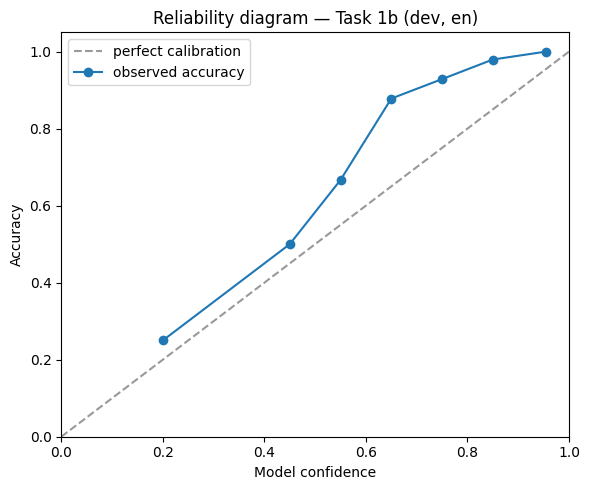

Saved -> /kaggle/working/aynvqa_1b/reliability_diagram_en.png


In [12]:
# 8c. Plot the reliability diagram (save as a figure for the paper)
import matplotlib.pyplot as plt

bin_centers, bin_accs, bin_counts = [], [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (confidences >= lo) & (confidences < hi)
    if mask.sum() > 0:
        bin_centers.append((lo + hi) / 2)
        bin_accs.append(corrects[mask].mean())
        bin_counts.append(mask.sum())

fig, ax1 = plt.subplots(figsize=(6, 5))
ax1.plot([0, 1], [0, 1], "k--", alpha=0.4, label="perfect calibration")
ax1.plot(bin_centers, bin_accs, "o-", color="tab:blue", label="observed accuracy")
ax1.set_xlabel("Model confidence")
ax1.set_ylabel("Accuracy")
ax1.set_title(f"Reliability diagram — Task 1b (dev, {LANG})")
ax1.legend(loc="upper left")
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1.05)

fig.tight_layout()
fig.savefig(f"{OUT_DIR}/reliability_diagram_{LANG}.png", dpi=150)
plt.show()
print(f"Saved -> {OUT_DIR}/reliability_diagram_{LANG}.png")

In [13]:
# 8d. Selective refinement via paraphrase ensembling (only for low-confidence items)
low_conf_results = [r for r in conf_results if r["confidence"] < CONFIDENCE_THRESHOLD]
print(f"{len(low_conf_results)}/{len(conf_results)} items flagged low-confidence "
      f"({100*len(low_conf_results)/len(conf_results):.1f}%)")

# Five paraphrased instruction variants (odd count avoids ties) — same semantic ask,
# different wording/order, to get a self-consistency signal without full-dataset-scale
# extra inference.
# v8: bumped 5 -> 7 variants (still odd, avoids ties) since raising CONFIDENCE_THRESHOLD
# means this now runs on a much larger, harder slice of dev (~18% vs ~10% before). Also
# reworded every variant to invite combining visible content with real-world/cultural
# knowledge instead of pure literal image-matching — see the DIRECT_INSTRUCTION_EN note
# in section 5 for why (fine-grained object/vessel/brand distinctions in the dev errors
# were not resolvable from pixels alone).
PARAPHRASE_INSTRUCTIONS_EN = [
    "You will see an image and three statements about it. Exactly ONE statement is "
    "actually correct for this image; the other two are plausible-sounding but wrong. "
    "Judge using both what is visible and any relevant real-world or cultural knowledge "
    "needed to tell the options apart. Reply with ONLY the number (0, 1, or 2) of the "
    "correct statement. Do not explain, just output the digit.",

    "Look closely at the image, and also draw on any relevant background knowledge about "
    "what's shown (the specific object, dish, or item type, not just its general look). "
    "Among the three statements below, only one is actually correct for this image — the "
    "others merely sound plausible. Respond with a single digit (0, 1, or 2). No explanation.",

    "Which of these three statements is actually correct for what is depicted in the "
    "image, using both the visual evidence and any real-world knowledge needed to "
    "distinguish similar-looking options? Two are decoys that sound reasonable but are "
    "wrong. Answer with just the index (0, 1, or 2).",

    "Examine the image carefully. Don't just match surface appearance — use what you know "
    "about the specific type of object/dish/item shown to pick the one statement that is "
    "actually correct, out of three. Output only its index: 0, 1, or 2.",

    "Three statements follow an image; two are distractors that sound reasonable but are "
    "factually wrong for this specific image. Identify the one correct statement, "
    "combining what's visible with relevant background knowledge, and answer with just "
    "its number (0, 1, or 2).",

    "Consider the image as a whole — the objects, setting, and any culturally specific "
    "details (vessel shapes, brands, ingredients, styles). Exactly one of the three "
    "statements below is correct for this specific image. Reply with only its digit "
    "(0, 1, or 2), nothing else.",

    "You are distinguishing between plausible-but-wrong statements and the one that is "
    "actually true of this image. Use fine-grained visual detail plus relevant real-world "
    "knowledge (not just a general category match) to decide. Answer with a single digit: "
    "0, 1, or 2.",
]


def build_messages_variant(image, statements, instruction):
    stmt_block = "\n".join(f"{i}: {s}" for i, s in enumerate(statements))
    text = f"{instruction}\n\n{stmt_block}"
    return [{"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": text}]}]


def refine_item(row):
    """Re-run the item with a few paraphrased prompts and majority-vote the index."""
    image = load_image(row["image"])
    statements = row["statements"]
    votes = []
    for instruction in PARAPHRASE_INSTRUCTIONS_EN:
        messages = build_messages_variant(image, statements, instruction)
        text_prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        image_inputs, video_inputs = process_vision_info(messages)
        inputs = processor(
            text=[text_prompt], images=image_inputs, videos=video_inputs,
            padding=True, return_tensors="pt",
        ).to(model.device)

        with torch.no_grad():
            generated = model.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False)

        trimmed = generated[:, inputs["input_ids"].shape[1]:]
        raw_text = processor.batch_decode(
            trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
        )[0].strip()

        vote = parse_index(raw_text)
        if vote is not None:
            votes.append(vote)

    if not votes:
        return row.get("chosen_index", 0)  # extremely unlikely, but don't crash the run

    from collections import Counter
    vote_counts = Counter(votes)
    return vote_counts.most_common(1)[0][0]


refined_results = []
for i, r in enumerate(low_conf_results):
    row = id_to_row[r["id"]]
    r["chosen_index_original"] = r["chosen_index"]
    new_choice = refine_item(row)
    refined_results.append({**r, "chosen_index_refined": new_choice})
    if (i + 1) % 10 == 0:
        print(f"refined {i+1}/{len(low_conf_results)}")

print(f"Refined {len(refined_results)} low-confidence dev items.")

209/500 items flagged low-confidence (41.8%)
refined 10/209
refined 20/209
refined 30/209
refined 40/209
refined 50/209
refined 60/209
refined 70/209
refined 80/209
refined 90/209
refined 100/209
refined 110/209
refined 120/209
refined 130/209
refined 140/209
refined 150/209
refined 160/209
refined 170/209
refined 180/209
refined 190/209
refined 200/209
Refined 209 low-confidence dev items.


In [14]:
# 8e. Compare accuracy before vs after selective refinement (dev only, for the paper)
n_changed = 0
n_changed_to_correct = 0
n_changed_to_incorrect = 0

refined_by_id = {r["id"]: r for r in refined_results}

final_results = []
for r in conf_results:
    if r["id"] in refined_by_id:
        rr = refined_by_id[r["id"]]
        final_choice = rr["chosen_index_refined"]
        if final_choice != rr["chosen_index_original"]:
            n_changed += 1
            labels = id_to_labels[r["id"]]
            true_idx = labels.index(True)
            was_correct = rr["chosen_index_original"] == true_idx
            now_correct = final_choice == true_idx
            if now_correct and not was_correct:
                n_changed_to_correct += 1
            elif was_correct and not now_correct:
                n_changed_to_incorrect += 1
        final_results.append({**r, "chosen_index": final_choice})
    else:
        final_results.append(r)

acc_before = corrects.mean()
acc_after = np.mean([is_correct(r) for r in final_results])

print(f"Accuracy before refinement: {acc_before:.4f}")
print(f"Accuracy after refinement:  {acc_after:.4f}")
print(f"Items changed:              {n_changed} / {len(low_conf_results)} flagged")
print(f"  -> changed wrong->right:  {n_changed_to_correct}")
print(f"  -> changed right->wrong:  {n_changed_to_incorrect}")
print()
print("This before/after comparison, plus the reliability diagram, is your core")
print("methodology result for the paper — report both numbers plus the country/category")
print("breakdown below as your error analysis.")

Accuracy before refinement: 0.9080
Accuracy after refinement:  0.9400
Items changed:              25 / 209 flagged
  -> changed wrong->right:  20
  -> changed right->wrong:  4

This before/after comparison, plus the reliability diagram, is your core
methodology result for the paper — report both numbers plus the country/category
breakdown below as your error analysis.


In [15]:
# 8f. Error breakdown by country/category (for the paper's cultural-grounding analysis)
import pandas as pd

rows_for_df = []
for r in final_results:
    labels = id_to_labels[r["id"]]
    true_idx = labels.index(True)
    rows_for_df.append({
        "id": r["id"],
        "country": r["country"],
        "category": r["category"],
        "correct": r["chosen_index"] == true_idx,
        "confidence": r["confidence"],
    })

df_errors = pd.DataFrame(rows_for_df)

print("Accuracy by country:")
print(df_errors.groupby("country")["correct"].agg(["mean", "count"]).sort_values("mean"))

print("\nAccuracy by category:")
print(df_errors.groupby("category")["correct"].agg(["mean", "count"]).sort_values("mean"))

df_errors.to_csv(f"{OUT_DIR}/error_breakdown_{LANG}.csv", index=False)
print(f"\nSaved -> {OUT_DIR}/error_breakdown_{LANG}.csv")

Accuracy by country:
                  mean  count
country                      
Bahrain       0.896552     29
Qatar         0.896552     29
Tunisia       0.896552     29
UAE           0.900000     30
Palestine     0.931034     29
Algeria       0.931034     29
Saudi Arabia  0.931034     29
Jordan        0.933333     30
Libya         0.933333     30
Syria         0.933333     30
Yemen         0.933333     30
Kuwait        0.965517     29
Morocco       0.965517     29
Lebanon       0.966667     30
Egypt         0.966667     30
Oman          1.000000     29
Sudan         1.000000     29

Accuracy by category:
                                            mean  count
category                                               
Geography, Buildings & Landmarks        0.852941     34
Food & Cooking                          0.906250     32
Objects, Materials & Clothing           0.934783     46
Religion & Spirituality                 0.938776     49
Sports & Recreation                     0.938776  

In [16]:
# 8g. Full metric comparison before vs after refinement (CI, CFHR, Q+/Q-)
# Reuses the score_1b() function defined earlier (section 7).

before_results_fmt = [
    {"id": r["id"], "chosen_index": r["chosen_index_original"] if r["id"] in refined_by_id else r["chosen_index"]}
    for r in conf_results
]
after_results_fmt = [{"id": r["id"], "chosen_index": r["chosen_index"]} for r in final_results]

metrics_before = score_1b(split_data, before_results_fmt)
metrics_after = score_1b(split_data, after_results_fmt)

print(f"{'metric':22s} {'before':>10s} {'after':>10s} {'delta':>10s}")
for k in metrics_before:
    if isinstance(metrics_before[k], float):
        delta = metrics_after[k] - metrics_before[k]
        print(f"{k:22s} {metrics_before[k]:10.4f} {metrics_after[k]:10.4f} {delta:+10.4f}")
    else:
        print(f"{k:22s} {metrics_before[k]:>10} {metrics_after[k]:>10}")

print()
print("This table is your headline results row for the paper: report all 5 metrics")
print("before/after, not just accuracy — CI and CFHR are the official ranking metrics.")

metric                     before      after      delta
n_items                       500        500
combined_accuracy          0.9080     0.9400    +0.0320
CI                         0.0920     0.0600    -0.0320
CFHR                       0.0000     0.0000    +0.0000
Qplus_accuracy             0.9080     0.9400    +0.0320
Qminus_accuracy            0.9540     0.9700    +0.0160

This table is your headline results row for the paper: report all 5 metrics
before/after, not just accuracy — CI and CFHR are the official ranking metrics.


In [17]:
# 8h. Diagnose errors in the weakest category (auto-selected from the breakdown above)
WEAK_CATEGORY = df_errors.groupby("category")["correct"].mean().idxmin()

weak_items = [row for row in split_data if row["category"] == WEAK_CATEGORY]
weak_ids = {row["id"] for row in weak_items}
weak_final = [r for r in final_results if r["id"] in weak_ids]

print(f"{len(weak_items)} items in '{WEAK_CATEGORY}' (weakest category by accuracy)")

wrong_cases = []
for r in weak_final:
    row = id_to_row[r["id"]]
    true_idx = row["labels"].index(True)
    if r["chosen_index"] != true_idx:
        wrong_cases.append({
            "id": r["id"],
            "country": row["country"],
            "statements": row["statements"],
            "true_idx": true_idx,
            "predicted_idx": r["chosen_index"],
            "confidence": r["confidence"],
        })

print(f"{len(wrong_cases)} wrong out of {len(weak_final)}\n")
for c in wrong_cases:
    print(f"id={c['id'][:12]}...  country={c['country']}  conf={c['confidence']:.2f}")
    print(f"  true statement (idx {c['true_idx']}): {c['statements'][c['true_idx']]}")
    print(f"  model picked  (idx {c['predicted_idx']}): {c['statements'][c['predicted_idx']]}")
    print()

34 items in 'Geography, Buildings & Landmarks' (weakest category by accuracy)
5 wrong out of 34

id=8ec40edc0a36...  country=Morocco  conf=0.58
  true statement (idx 0): The primary material used in the construction of the ancient site shown in the image is brick. True or False?
  model picked  (idx 1): The primary material used in the construction of the ancient site shown in the image is stone. True or False?

id=fbea989c5695...  country=Qatar  conf=0.34
  true statement (idx 0): The primary function of the stone well depicted in the foreground is to provide water for public use. True or False?
  model picked  (idx 2): The primary function of the stone well depicted in the foreground is to serve as a decorative feature. True or False?

id=3f945d825ac6...  country=Qatar  conf=0.49
  true statement (idx 2): The primary function of the small kiosk-like structures in front of the building is to display and sell rugs or carpets. True or False?
  model picked  (idx 1): The primary function

## 9. Generate + zip the submission (devtest / test)

Per the official schedule (checked July 24, 2026 against https://imageeval2026.github.io/):
`devtest` is available now, but the blind `test` split releases **August 2, 2026** and the
evaluation cycle (run submission) closes **August 7, 2026**. Both pipelines below return
`None` for `test` until then — re-run after Aug 2 to also generate it.

**Pick ONE of the two, based on what section 7b showed:**

- **Direct prompt won or tied (the expected default)** — use
  `run_refined_pipeline(split_name)`. It applies the confidence threshold and
  paraphrase-ensemble method validated on `dev` above.
- **CoT won** — use `run_simple_pipeline(split_name)` instead, with `USE_COT_PROMPT = True`
  set in the config cell. The confidence-extraction step in section 8 assumes the digit is
  the first generated token, so it isn't compatible with CoT's reasoning-then-digit output;
  don't mix the two.

Either path writes the CSV via `write_submission_csv` (correct lowercase booleans),
`validate_submission`s it locally, then zips it. Upload to Codabench 17051 (English 1b) or
17050 (MSA 1b).

In [18]:
# 9a. One reusable pipeline: confidence-extract -> selectively refine -> submission CSV -> zip
import zipfile

def run_refined_pipeline(split_name, lang=LANG):
    """
    Loads `split_name` (e.g. "devtest" or "test"), runs confidence-extracting inference,
    refines only the low-confidence items via paraphrase-ensemble voting, writes the
    submission CSV, validates it, and zips it for Codabench. Returns the zip path, or None
    if the split isn't available on HF yet.
    """
    try:
        data = load_split(split_name, lang=lang)
    except Exception as e:
        print(f"{split_name}: not available yet on HF ({e}) — skipping.")
        return None

    print(f"Loaded {len(data)} {split_name} records")
    id_to_row_local = {row["id"]: row for row in data}

    conf = run_inference_with_confidence(data, limit=None)
    low_conf = [r for r in conf if r["confidence"] < CONFIDENCE_THRESHOLD]
    print(f"{len(low_conf)}/{len(conf)} {split_name} items flagged low-confidence "
          f"({100*len(low_conf)/len(conf):.1f}%)")

    refined = []
    for i, r in enumerate(low_conf):
        row = id_to_row_local[r["id"]]
        r["chosen_index_original"] = r["chosen_index"]
        new_choice = refine_item(row)
        refined.append({**r, "chosen_index_refined": new_choice})
        if (i + 1) % 10 == 0:
            print(f"refined {i+1}/{len(low_conf)}")
    print(f"Refined {len(refined)} low-confidence {split_name} items.")

    refined_by_id_local = {r["id"]: r for r in refined}
    final = []
    for r in conf:
        if r["id"] in refined_by_id_local:
            final_choice = refined_by_id_local[r["id"]]["chosen_index_refined"]
            final.append({**r, "chosen_index": final_choice})
        else:
            final.append(r)

    rows = to_submission_rows(final)
    csv_path = f"{OUT_DIR}/{split_name}_{lang}_predictions_refined.csv"
    df = write_submission_csv(rows, csv_path)
    validate_submission(df, data)
    print(f"Wrote {len(df)} rows -> {csv_path}")

    zip_path = f"{OUT_DIR}/prediction_{lang}_{split_name}_refined.zip"
    with zipfile.ZipFile(zip_path, "w") as zf:
        zf.write(csv_path, arcname="prediction.csv")
    print(f"Zipped -> {zip_path}\n")
    return zip_path


def run_simple_pipeline(split_name, lang=LANG):
    """
    CoT-compatible alternative to run_refined_pipeline: plain batched inference (respects
    USE_COT_PROMPT), no confidence extraction or paraphrase refinement. Use this branch if
    section 7b showed CoT winning on dev. Returns the zip path, or None if unavailable.
    """
    try:
        data = load_split(split_name, lang=lang)
    except Exception as e:
        print(f"{split_name}: not available yet on HF ({e}) — skipping.")
        return None

    print(f"Loaded {len(data)} {split_name} records (USE_COT_PROMPT={USE_COT_PROMPT})")
    results = run_inference_batched(data, limit=None)
    rows = to_submission_rows(results)

    csv_path = f"{OUT_DIR}/{split_name}_{lang}_predictions_simple.csv"
    df = write_submission_csv(rows, csv_path)
    validate_submission(df, data)
    print(f"Wrote {len(df)} rows -> {csv_path}")

    zip_path = f"{OUT_DIR}/prediction_{lang}_{split_name}_simple.zip"
    with zipfile.ZipFile(zip_path, "w") as zf:
        zf.write(csv_path, arcname="prediction.csv")
    print(f"Zipped -> {zip_path}\n")
    return zip_path


# Pick ONE path per the note above — running both is harmless but wasteful.
# devtest_zip = run_refined_pipeline("devtest")  # skip — only need test right now
test_zip = run_refined_pipeline("test")

# devtest_zip_simple = run_simple_pipeline("devtest")
# test_zip_simple = run_simple_pipeline("test")

print("Upload the zip(s) above to the matching Codabench leaderboard (17051 EN / 17050 MSA).")

test_en.jsonl: 0.00B [00:00, ?B/s]

Loaded 1000 test records


images/d523470f46ecf484d22c505e0f04bb945(…):   0%|          | 0.00/46.7k [00:00<?, ?B/s]

images/79459a096744e00f8927f694a511f6566(…):   0%|          | 0.00/363k [00:00<?, ?B/s]

images/f479b4fb03eff6c28b55d5678aca7ff09(…):   0%|          | 0.00/320k [00:00<?, ?B/s]

...

images/9ba00b41485bca804d912a80fcdd0cb8b(…):   0%|          | 0.00/266k [00:00<?, ?B/s]

images/5e4dba0c9dace483c31f28d8aa86c55c4(…):   0%|          | 0.00/210k [00:00<?, ?B/s]

images/8267680b28a35adfa1f9d782f109fd87f(…):   0%|          | 0.00/170k [00:00<?, ?B/s]

images/e47618495e7b19876c12750f9f9febfbc(…):   0%|          | 0.00/160k [00:00<?, ?B/s]

1000/1000 done
459/1000 test items flagged low-confidence (45.9%)
refined 10/459
refined 20/459
refined 30/459
refined 40/459
refined 50/459
refined 60/459
refined 70/459
refined 80/459
refined 90/459
refined 100/459
refined 110/459
refined 120/459
refined 130/459
refined 140/459
refined 150/459
refined 160/459
refined 170/459
refined 180/459
refined 190/459
refined 200/459
refined 210/459
refined 220/459
refined 230/459
refined 240/459
refined 250/459
refined 260/459
refined 270/459
refined 280/459
refined 290/459
refined 300/459
refined 310/459
refined 320/459
refined 330/459
refined 340/459
refined 350/459
refined 360/459
refined 370/459
refined 380/459
refined 390/459
refined 400/459
refined 410/459
refined 420/459
refined 430/459
refined 440/459
refined 450/459
Refined 459 low-confidence test items.
validate_submission: OK — 1000 ids, 3000 rows, format matches spec.
Wrote 3000 rows -> /kaggle/working/aynvqa_1b/test_en_predictions_refined.csv
Zipped -> /kaggle/working/aynvqa_1b/pre

## 10. Gold-test evaluation and publication-quality figures

The blind-test gold labels are now available. The cells below:

1. load the released Task 1B English/MSA test labels,
2. align them with the **saved final submission** produced in Section 9,
3. recompute the official Task 1B metrics locally,
4. create publication-quality vector figures (`.pdf`) plus high-resolution `.png` copies.

The loader checks the released `QCRI/ImageEval-ArabicNLP26` dataset first and falls back to
`QCRI/AynVQA-ArabicNLP26`. It accepts the split only when non-null gold `labels` are actually present,
so it will not silently score against an unlabeled blind-test file.


In [19]:
# 10a. Load released gold test labels + align with the saved final prediction CSV
from datasets import load_dataset
from pathlib import Path
import pandas as pd
import numpy as np
import os

GOLD_REPOS = [
    "QCRI/ImageEval-ArabicNLP26",  # released viewer supplied after the competition
    "QCRI/AynVQA-ArabicNLP26",     # current dataset name / fallback
]
CONFIG_NAME = f"task1b_{LANG}"

def _valid_gold_rows(rows):
    if len(rows) == 0:
        return False
    first = rows[0]
    if "labels" not in first or first["labels"] is None:
        return False
    labels = first["labels"]
    return isinstance(labels, (list, tuple)) and len(labels) == 3 and sum(bool(x) for x in labels) == 1

gold_test = None
gold_repo_used = None
gold_errors = []

for repo_id in GOLD_REPOS:
    try:
        ds = load_dataset(repo_id, CONFIG_NAME, split="test")
        rows = [dict(x) for x in ds]
        if _valid_gold_rows(rows):
            gold_test = rows
            gold_repo_used = repo_id
            break
        gold_errors.append(f"{repo_id}: test split loaded, but gold labels were absent/null")
    except Exception as e:
        gold_errors.append(f"{repo_id}: {type(e).__name__}: {e}")

if gold_test is None:
    raise RuntimeError(
        "Could not find released non-null gold test labels.\n"
        + "\n".join(gold_errors)
        + "\nOpen the released HF viewer and verify that the Task 1B test split contains `labels`."
    )

print(f"Gold source: {gold_repo_used} / {CONFIG_NAME} / test")
print(f"Gold items : {len(gold_test)}")
print("Example labels:", gold_test[0]["labels"])

# Find the final test prediction CSV already produced by Section 9.
prediction_candidates = [
    Path(OUT_DIR) / f"test_{LANG}_predictions_refined.csv",
    Path(OUT_DIR) / f"test_{LANG}_predictions_simple.csv",
]

pred_path = next((p for p in prediction_candidates if p.exists()), None)
if pred_path is None:
    raise FileNotFoundError(
        "No saved test prediction CSV found. Run Section 9 first.\nTried:\n"
        + "\n".join(str(p) for p in prediction_candidates)
    )

pred_long = pd.read_csv(pred_path)
pred_long["prediction_bool"] = (
    pred_long["prediction"].astype(str).str.strip().str.lower().map(
        {"true": True, "false": False, "1": True, "0": False}
    )
)

if pred_long["prediction_bool"].isna().any():
    bad = pred_long.loc[pred_long["prediction_bool"].isna(), "prediction"].unique()
    raise ValueError(f"Unparseable prediction values: {bad}")

# Recover the one selected/grounded index per item from the 3-row submission.
pred_index = (
    pred_long.loc[pred_long["prediction_bool"]]
    .set_index("id")["statement_index"]
    .astype(int)
    .to_dict()
)

gold_by_id = {r["id"]: r for r in gold_test}
missing = set(gold_by_id) - set(pred_index)
extra = set(pred_index) - set(gold_by_id)
assert not missing and not extra, f"ID mismatch: {len(missing)} missing, {len(extra)} extra"

test_results = []
for item_id, row in gold_by_id.items():
    true_idx = [bool(x) for x in row["labels"]].index(True)
    test_results.append({
        "id": item_id,
        "true_index": true_idx,
        "pred_index": int(pred_index[item_id]),
        "correct": int(pred_index[item_id]) == true_idx,
        "statements": row.get("statements"),
    })

test_eval_df = pd.DataFrame(test_results)
test_final_results = [
    {"id": r["id"], "chosen_index": int(r["pred_index"])}
    for _, r in test_eval_df.iterrows()
]

test_metrics = score_1b(gold_test, test_final_results)

print(f"\nFinal prediction file: {pred_path}")
print("\nOfficial Task 1B metrics on released TEST gold:")
for k, v in test_metrics.items():
    if isinstance(v, float):
        print(f"{k:22s} {v:.4f}")
    else:
        print(f"{k:22s} {v}")

pd.DataFrame([test_metrics]).to_csv(
    Path(OUT_DIR) / f"test_gold_metrics_{LANG}.csv", index=False
)
test_eval_df.to_csv(
    Path(OUT_DIR) / f"test_gold_itemwise_{LANG}.csv", index=False
)
print(f"\nSaved metrics/itemwise files in {OUT_DIR}")


README.md: 0.00B [00:00, ?B/s]

train_en.jsonl: 0.00B [00:00, ?B/s]

dev_en.jsonl: 0.00B [00:00, ?B/s]

devtest_en.jsonl: 0.00B [00:00, ?B/s]

test_en.jsonl: 0.00B [00:00, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating dev split: 0 examples [00:00, ? examples/s]

Generating devtest split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Gold source: QCRI/ImageEval-ArabicNLP26 / task1b_en / test
Gold items : 1000
Example labels: [False, True, False]

Final prediction file: /kaggle/working/aynvqa_1b/test_en_predictions_refined.csv

Official Task 1B metrics on released TEST gold:
n_items                1000
combined_accuracy      0.9420
CI                     0.0580
CFHR                   0.0000
Qplus_accuracy         0.9420
Qminus_accuracy        0.9710

Saved metrics/itemwise files in /kaggle/working/aynvqa_1b


In [20]:
# 10b. Paper figure style helper
# Creates vector PDF figures for LaTeX plus 600-dpi PNG copies for easy inspection.

import matplotlib.pyplot as plt
from pathlib import Path

FIG_DIR = Path(OUT_DIR) / "paper_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 120,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def save_paper_figure(fig, stem):
    pdf_path = FIG_DIR / f"{stem}.pdf"
    png_path = FIG_DIR / f"{stem}.png"
    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, dpi=600, bbox_inches="tight")
    print("Saved:", pdf_path)
    print("Saved:", png_path)


Saved: /kaggle/working/aynvqa_1b/paper_figures/fig_test_position_confusion_en.pdf
Saved: /kaggle/working/aynvqa_1b/paper_figures/fig_test_position_confusion_en.png


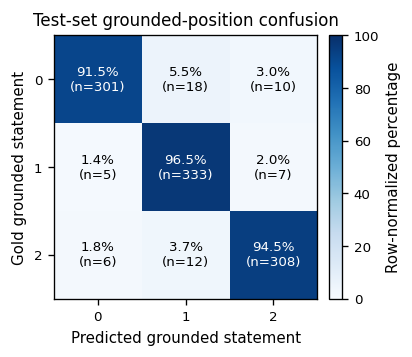


Raw confusion matrix:
        Pred 0  Pred 1  Pred 2
Gold 0     301      18      10
Gold 1       5     333       7
Gold 2       6      12     308


In [21]:
# 10c. FIGURE 1 — Gold grounded-position vs predicted-position confusion matrix
# Useful in the Results/Error Analysis section: it reveals systematic option-position bias.

cm = np.zeros((3, 3), dtype=int)
for row in test_eval_df.itertuples(index=False):
    cm[row.true_index, row.pred_index] += 1

row_totals = cm.sum(axis=1, keepdims=True)
cm_pct = np.divide(cm, row_totals, out=np.zeros_like(cm, dtype=float), where=row_totals != 0) * 100

fig, ax = plt.subplots(figsize=(3.45, 3.05))
im = ax.imshow(cm_pct, vmin=0, vmax=100, cmap="Blues")

ax.set_xticks([0, 1, 2])
ax.set_yticks([0, 1, 2])
ax.set_xlabel("Predicted grounded statement")
ax.set_ylabel("Gold grounded statement")
ax.set_title("Test-set grounded-position confusion")

for i in range(3):
    for j in range(3):
        value = cm_pct[i, j]
        text_color = "white" if value >= 50 else "black"
        ax.text(
            j, i,
            f"{value:.1f}%\n(n={cm[i, j]})",
            ha="center", va="center",
            fontsize=8, color=text_color
        )

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Row-normalized percentage")

fig.tight_layout()
save_paper_figure(fig, f"fig_test_position_confusion_{LANG}")
plt.show()

print("\nRaw confusion matrix:")
print(pd.DataFrame(
    cm,
    index=["Gold 0", "Gold 1", "Gold 2"],
    columns=["Pred 0", "Pred 1", "Pred 2"]
))


Saved: /kaggle/working/aynvqa_1b/paper_figures/fig_test_accuracy_by_position_en.pdf
Saved: /kaggle/working/aynvqa_1b/paper_figures/fig_test_accuracy_by_position_en.png


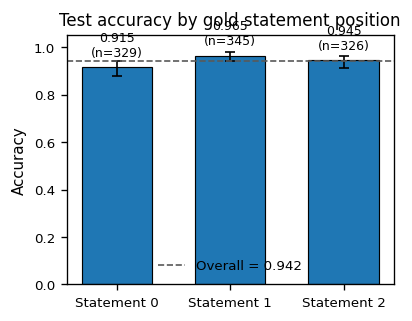

,position,n,correct,accuracy,ci_low,ci_high
0,0,329,301,0.914894,0.879747,0.940463
1,1,345,333,0.965217,0.940195,0.979993
2,2,326,308,0.944785,0.914418,0.964792


In [22]:
# 10d. FIGURE 2 — Accuracy by grounded-statement position with 95% Wilson intervals
# This is more publication-worthy than a simple count plot because it reports uncertainty.

def wilson_interval(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2*n)) / denom
    half = z * np.sqrt((p*(1-p) + z**2/(4*n)) / n) / denom
    return center - half, center + half

position_rows = []
for idx in [0, 1, 2]:
    g = test_eval_df[test_eval_df["true_index"] == idx]
    n = len(g)
    k = int(g["correct"].sum())
    acc = k / n if n else np.nan
    lo, hi = wilson_interval(k, n)
    position_rows.append({
        "position": idx, "n": n, "correct": k,
        "accuracy": acc, "ci_low": lo, "ci_high": hi
    })

position_df = pd.DataFrame(position_rows)

x = np.arange(3)
y = position_df["accuracy"].to_numpy()
yerr = np.vstack([
    y - position_df["ci_low"].to_numpy(),
    position_df["ci_high"].to_numpy() - y
])

fig, ax = plt.subplots(figsize=(3.45, 2.75))
bars = ax.bar(x, y, width=0.62, edgecolor="black", linewidth=0.7)
ax.errorbar(x, y, yerr=yerr, fmt="none", ecolor="black", capsize=3, linewidth=1)

ax.axhline(test_eval_df["correct"].mean(), linestyle="--", linewidth=1, color="0.35",
           label=f"Overall = {test_eval_df['correct'].mean():.3f}")
ax.set_xticks(x)
ax.set_xticklabels(["Statement 0", "Statement 1", "Statement 2"])
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Test accuracy by gold statement position")
ax.legend(frameon=False)

for rect, row in zip(bars, position_df.itertuples(index=False)):
    ax.text(
        rect.get_x() + rect.get_width()/2,
        min(row.accuracy + 0.035, 1.01),
        f"{row.accuracy:.3f}\n(n={row.n})",
        ha="center", va="bottom", fontsize=7.5
    )

fig.tight_layout()
save_paper_figure(fig, f"fig_test_accuracy_by_position_{LANG}")
plt.show()

position_df.to_csv(FIG_DIR / f"test_accuracy_by_position_{LANG}.csv", index=False)
position_df


### 10e. Optional but strongly recommended: test-set refinement analysis

Your final submission CSV contains only the **post-refinement** choice, so it cannot by itself show what
the confidence-gated paraphrase ensemble changed. The next cell performs **one direct confidence pass**
over the 1,000 test items to recover the original choice and first-token confidence.

It does **not** rerun the 7-way paraphrase ensemble. The already-saved final submission is used as the
post-refinement output. This gives a clean test-set before/after analysis for the methodology section.


In [23]:
# 10e. One extra DIRECT pass: recover original test choices/confidence, then compare with saved final predictions.
# This is much cheaper than rerunning the full selective-refinement pipeline.

# Ensure image loading uses the actual repo that supplied the gold/test rows when possible.
# The current loader in Section 6 uses the global HF_DATASET for image downloads.
_original_hf_dataset = HF_DATASET
if gold_repo_used in GOLD_REPOS:
    HF_DATASET = gold_repo_used

test_conf_original = run_inference_with_confidence(gold_test, limit=None)

# Restore the original repo setting after inference.
HF_DATASET = _original_hf_dataset

original_pred_by_id = {r["id"]: int(r["chosen_index"]) for r in test_conf_original}
confidence_by_id = {r["id"]: float(r["confidence"]) for r in test_conf_original}

analysis_rows = []
for row in test_eval_df.itertuples(index=False):
    orig = original_pred_by_id[row.id]
    final = int(row.pred_index)
    analysis_rows.append({
        "id": row.id,
        "true_index": int(row.true_index),
        "original_index": orig,
        "final_index": final,
        "confidence": confidence_by_id[row.id],
        "original_correct": orig == int(row.true_index),
        "final_correct": final == int(row.true_index),
        "changed": orig != final,
    })

test_refine_df = pd.DataFrame(analysis_rows)

original_results_fmt = [
    {"id": r["id"], "chosen_index": int(r["original_index"])}
    for _, r in test_refine_df.iterrows()
]
final_results_fmt = [
    {"id": r["id"], "chosen_index": int(r["final_index"])}
    for _, r in test_refine_df.iterrows()
]

test_metrics_before = score_1b(gold_test, original_results_fmt)
test_metrics_after = score_1b(gold_test, final_results_fmt)

wrong_to_right = int(((~test_refine_df["original_correct"]) & test_refine_df["final_correct"]).sum())
right_to_wrong = int((test_refine_df["original_correct"] & (~test_refine_df["final_correct"])).sum())
changed_total = int(test_refine_df["changed"].sum())

print(f"Changed decisions: {changed_total}/{len(test_refine_df)}")
print(f"Wrong -> right   : {wrong_to_right}")
print(f"Right -> wrong   : {right_to_wrong}")
print(f"Net corrected    : {wrong_to_right - right_to_wrong}")

print(f"\n{'metric':22s} {'before':>10s} {'after':>10s} {'delta':>10s}")
for k in test_metrics_before:
    if isinstance(test_metrics_before[k], float):
        delta = test_metrics_after[k] - test_metrics_before[k]
        print(f"{k:22s} {test_metrics_before[k]:10.4f} {test_metrics_after[k]:10.4f} {delta:+10.4f}")

test_refine_df.to_csv(FIG_DIR / f"test_refinement_itemwise_{LANG}.csv", index=False)
pd.DataFrame([
    {"stage": "before_refinement", **test_metrics_before},
    {"stage": "after_refinement", **test_metrics_after},
]).to_csv(FIG_DIR / f"test_refinement_metrics_{LANG}.csv", index=False)


25/1000 done
50/1000 done
75/1000 done
100/1000 done
125/1000 done
150/1000 done
175/1000 done
200/1000 done
225/1000 done
250/1000 done
275/1000 done
300/1000 done
325/1000 done
350/1000 done
375/1000 done
400/1000 done
425/1000 done
450/1000 done
475/1000 done
500/1000 done
525/1000 done
550/1000 done
575/1000 done
600/1000 done
625/1000 done
650/1000 done
675/1000 done
700/1000 done
725/1000 done
750/1000 done
775/1000 done
800/1000 done
825/1000 done
850/1000 done
875/1000 done
900/1000 done
925/1000 done
950/1000 done
975/1000 done
1000/1000 done
Changed decisions: 50/1000
Wrong -> right   : 42
Right -> wrong   : 6
Net corrected    : 36

metric                     before      after      delta
combined_accuracy          0.9060     0.9420    +0.0360
CI                         0.0940     0.0580    -0.0360
CFHR                       0.0000     0.0000    +0.0000
Qplus_accuracy             0.9060     0.9420    +0.0360
Qminus_accuracy            0.9530     0.9710    +0.0180


Saved: /kaggle/working/aynvqa_1b/paper_figures/fig_test_refinement_by_confidence_en.pdf
Saved: /kaggle/working/aynvqa_1b/paper_figures/fig_test_refinement_by_confidence_en.png


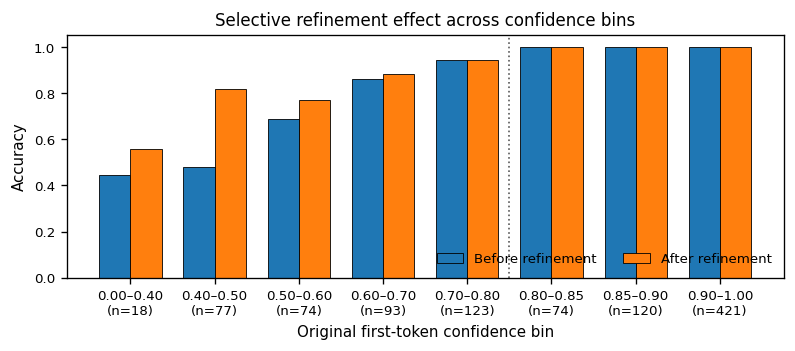

,label,lo,hi,n,before,after,changed
0,0.00–0.40,0.00,0.40,18,0.444444,0.555556,10
1,0.40–0.50,0.40,0.50,77,0.480519,0.818182,32
2,0.50–0.60,0.50,0.60,74,0.689189,0.770270,6
3,0.60–0.70,0.60,0.70,93,0.860215,0.881720,2
4,0.70–0.80,0.70,0.80,123,0.943089,0.943089,0
5,0.80–0.85,0.80,0.85,74,1.000000,1.000000,0
6,0.85–0.90,0.85,0.90,120,1.000000,1.000000,0
7,0.90–1.00,0.90,1.01,421,0.997625,0.997625,0


In [24]:
# 10f. FIGURE 3 — Accuracy before vs after refinement across original-confidence bins
# This directly tests whether the confidence gate targets the difficult region.

CONF_BINS = [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, CONFIDENCE_THRESHOLD, 0.9, 1.01]
CONF_BINS = sorted(set(round(float(x), 6) for x in CONF_BINS))
CONF_BINS = [x for x in CONF_BINS if 0 <= x <= 1.01]

bin_rows = []
for lo, hi in zip(CONF_BINS[:-1], CONF_BINS[1:]):
    mask = (test_refine_df["confidence"] >= lo) & (test_refine_df["confidence"] < hi)
    g = test_refine_df.loc[mask]
    if len(g) == 0:
        continue
    bin_rows.append({
        "label": f"{lo:.2f}–{min(hi, 1.0):.2f}",
        "lo": lo, "hi": hi, "n": len(g),
        "before": g["original_correct"].mean(),
        "after": g["final_correct"].mean(),
        "changed": g["changed"].sum(),
    })

conf_bin_df = pd.DataFrame(bin_rows)

x = np.arange(len(conf_bin_df))
width = 0.37

fig, ax = plt.subplots(figsize=(6.7, 3.0))
b1 = ax.bar(x - width/2, conf_bin_df["before"], width, label="Before refinement",
            edgecolor="black", linewidth=0.5)
b2 = ax.bar(x + width/2, conf_bin_df["after"], width, label="After refinement",
            edgecolor="black", linewidth=0.5)

ax.axvline(
    max(-0.5, np.searchsorted(conf_bin_df["hi"].to_numpy(), CONFIDENCE_THRESHOLD, side="left") - 0.5),
    linestyle=":", linewidth=1, color="0.35"
)
ax.set_xticks(x)
ax.set_xticklabels(
    [f"{r.label}\n(n={r.n})" for r in conf_bin_df.itertuples(index=False)],
    rotation=0
)
ax.set_xlabel("Original first-token confidence bin")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Selective refinement effect across confidence bins")
ax.legend(frameon=False, ncol=2, loc="lower right")

fig.tight_layout()
save_paper_figure(fig, f"fig_test_refinement_by_confidence_{LANG}")
plt.show()

conf_bin_df.to_csv(FIG_DIR / f"test_refinement_by_confidence_{LANG}.csv", index=False)
conf_bin_df


Saved: /kaggle/working/aynvqa_1b/paper_figures/fig_test_refinement_overall_en.pdf
Saved: /kaggle/working/aynvqa_1b/paper_figures/fig_test_refinement_overall_en.png


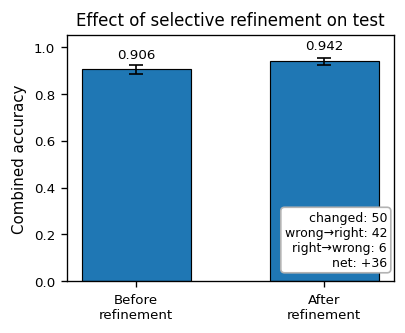


Paper-ready headline:
Combined accuracy changed from 0.9060 to 0.9420; 42 errors were corrected and 6 correct decisions were overturned.
CI changed from 0.0940 to 0.0580; CFHR remained 0.0000 under the exactly-one-True decoding constraint.


In [25]:
# 10g. FIGURE 4 — Overall test accuracy before/after + decision-change audit
# Compact summary figure for the methodology/result section.

def binomial_ci_from_bool(values):
    values = np.asarray(values, dtype=bool)
    k, n = int(values.sum()), len(values)
    lo, hi = wilson_interval(k, n)
    return values.mean(), lo, hi

acc_b, lo_b, hi_b = binomial_ci_from_bool(test_refine_df["original_correct"])
acc_a, lo_a, hi_a = binomial_ci_from_bool(test_refine_df["final_correct"])

fig, ax = plt.subplots(figsize=(3.45, 2.85))
vals = [acc_b, acc_a]
errs = np.array([
    [acc_b - lo_b, acc_a - lo_a],
    [hi_b - acc_b, hi_a - acc_a]
])

bars = ax.bar([0, 1], vals, width=0.58, edgecolor="black", linewidth=0.7)
ax.errorbar([0, 1], vals, yerr=errs, fmt="none", ecolor="black", capsize=4, linewidth=1)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Before\nrefinement", "After\nrefinement"])
ax.set_ylabel("Combined accuracy")
ax.set_ylim(0, 1.05)
ax.set_title("Effect of selective refinement on test")

for rect, value in zip(bars, vals):
    ax.text(
        rect.get_x() + rect.get_width()/2,
        min(value + 0.035, 1.01),
        f"{value:.3f}",
        ha="center", va="bottom", fontsize=8
    )

summary_text = (
    f"changed: {changed_total}\n"
    f"wrong→right: {wrong_to_right}\n"
    f"right→wrong: {right_to_wrong}\n"
    f"net: {wrong_to_right - right_to_wrong:+d}"
)
ax.text(
    0.98, 0.05, summary_text,
    transform=ax.transAxes, ha="right", va="bottom",
    fontsize=7.5,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="0.7")
)

fig.tight_layout()
save_paper_figure(fig, f"fig_test_refinement_overall_{LANG}")
plt.show()

print("\nPaper-ready headline:")
print(
    f"Combined accuracy changed from {acc_b:.4f} to {acc_a:.4f}; "
    f"{wrong_to_right} errors were corrected and {right_to_wrong} correct decisions were overturned."
)
print(
    f"CI changed from {test_metrics_before['CI']:.4f} to {test_metrics_after['CI']:.4f}; "
    f"CFHR remained {test_metrics_after['CFHR']:.4f} under the exactly-one-True decoding constraint."
)
